In [1]:
import sys
import os

from matplotlib import pyplot as plt

import numpy as np
import pandas as pd

from sklearn.decomposition import PCA
from sklearn.cross_decomposition import CCA


sys.path.append(os.path.join(os.getcwd(), '../import'))

from utils import read_utils
from utils import plot_utils
from utils import train_utils

In [2]:
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_')
filenames, continuous_behaviors, discrete_states, eigenworms, kymographs, traces = read_utils.get_data(path)

In [3]:
selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

In [4]:
n = 2

modes_manifold = (list(), list())
recon_manifold = (list(), list())
vars_expl = list()
vars_expl_rs = list()  # variance explained with respect to the reconstructed PCA data
for trace, ds in zip(traces, discrete_states):

	pca = PCA(n_components=5)
	trace_reduced_pca = pca.fit_transform(trace)
	trace_reconstructed_pca = pca.inverse_transform(trace_reduced_pca)

	cca = CCA(n_components=n, scale=True)
	trace_reduced, ds_reduced = cca.fit_transform(trace_reconstructed_pca, ds[selection].values)
	trace_reconstructed, ds_reconstructed = cca.inverse_transform(trace_reduced, ds_reduced)

	modes_manifold[0].append(pd.DataFrame(data=trace_reduced, columns=[f'CC{i + 1}' for i in range(n)]))
	modes_manifold[1].append(pd.DataFrame(data=ds_reduced, columns=[f'CC{i + 1}' for i in range(n)]))
	recon_manifold[0].append(pd.DataFrame(data=trace_reconstructed, columns=trace.columns))
	recon_manifold[1].append(pd.DataFrame(data=ds_reconstructed, columns=ds[selection].columns))

	var_ratio = train_utils.get_variance_explained(trace, trace_reconstructed)
	var_ratio_rs = train_utils.get_variance_explained(trace_reconstructed_pca, trace_reconstructed)
	vars_expl.append(var_ratio)
	vars_expl_rs.append(var_ratio_rs)

0.4292433410404884 0.6894107969741856


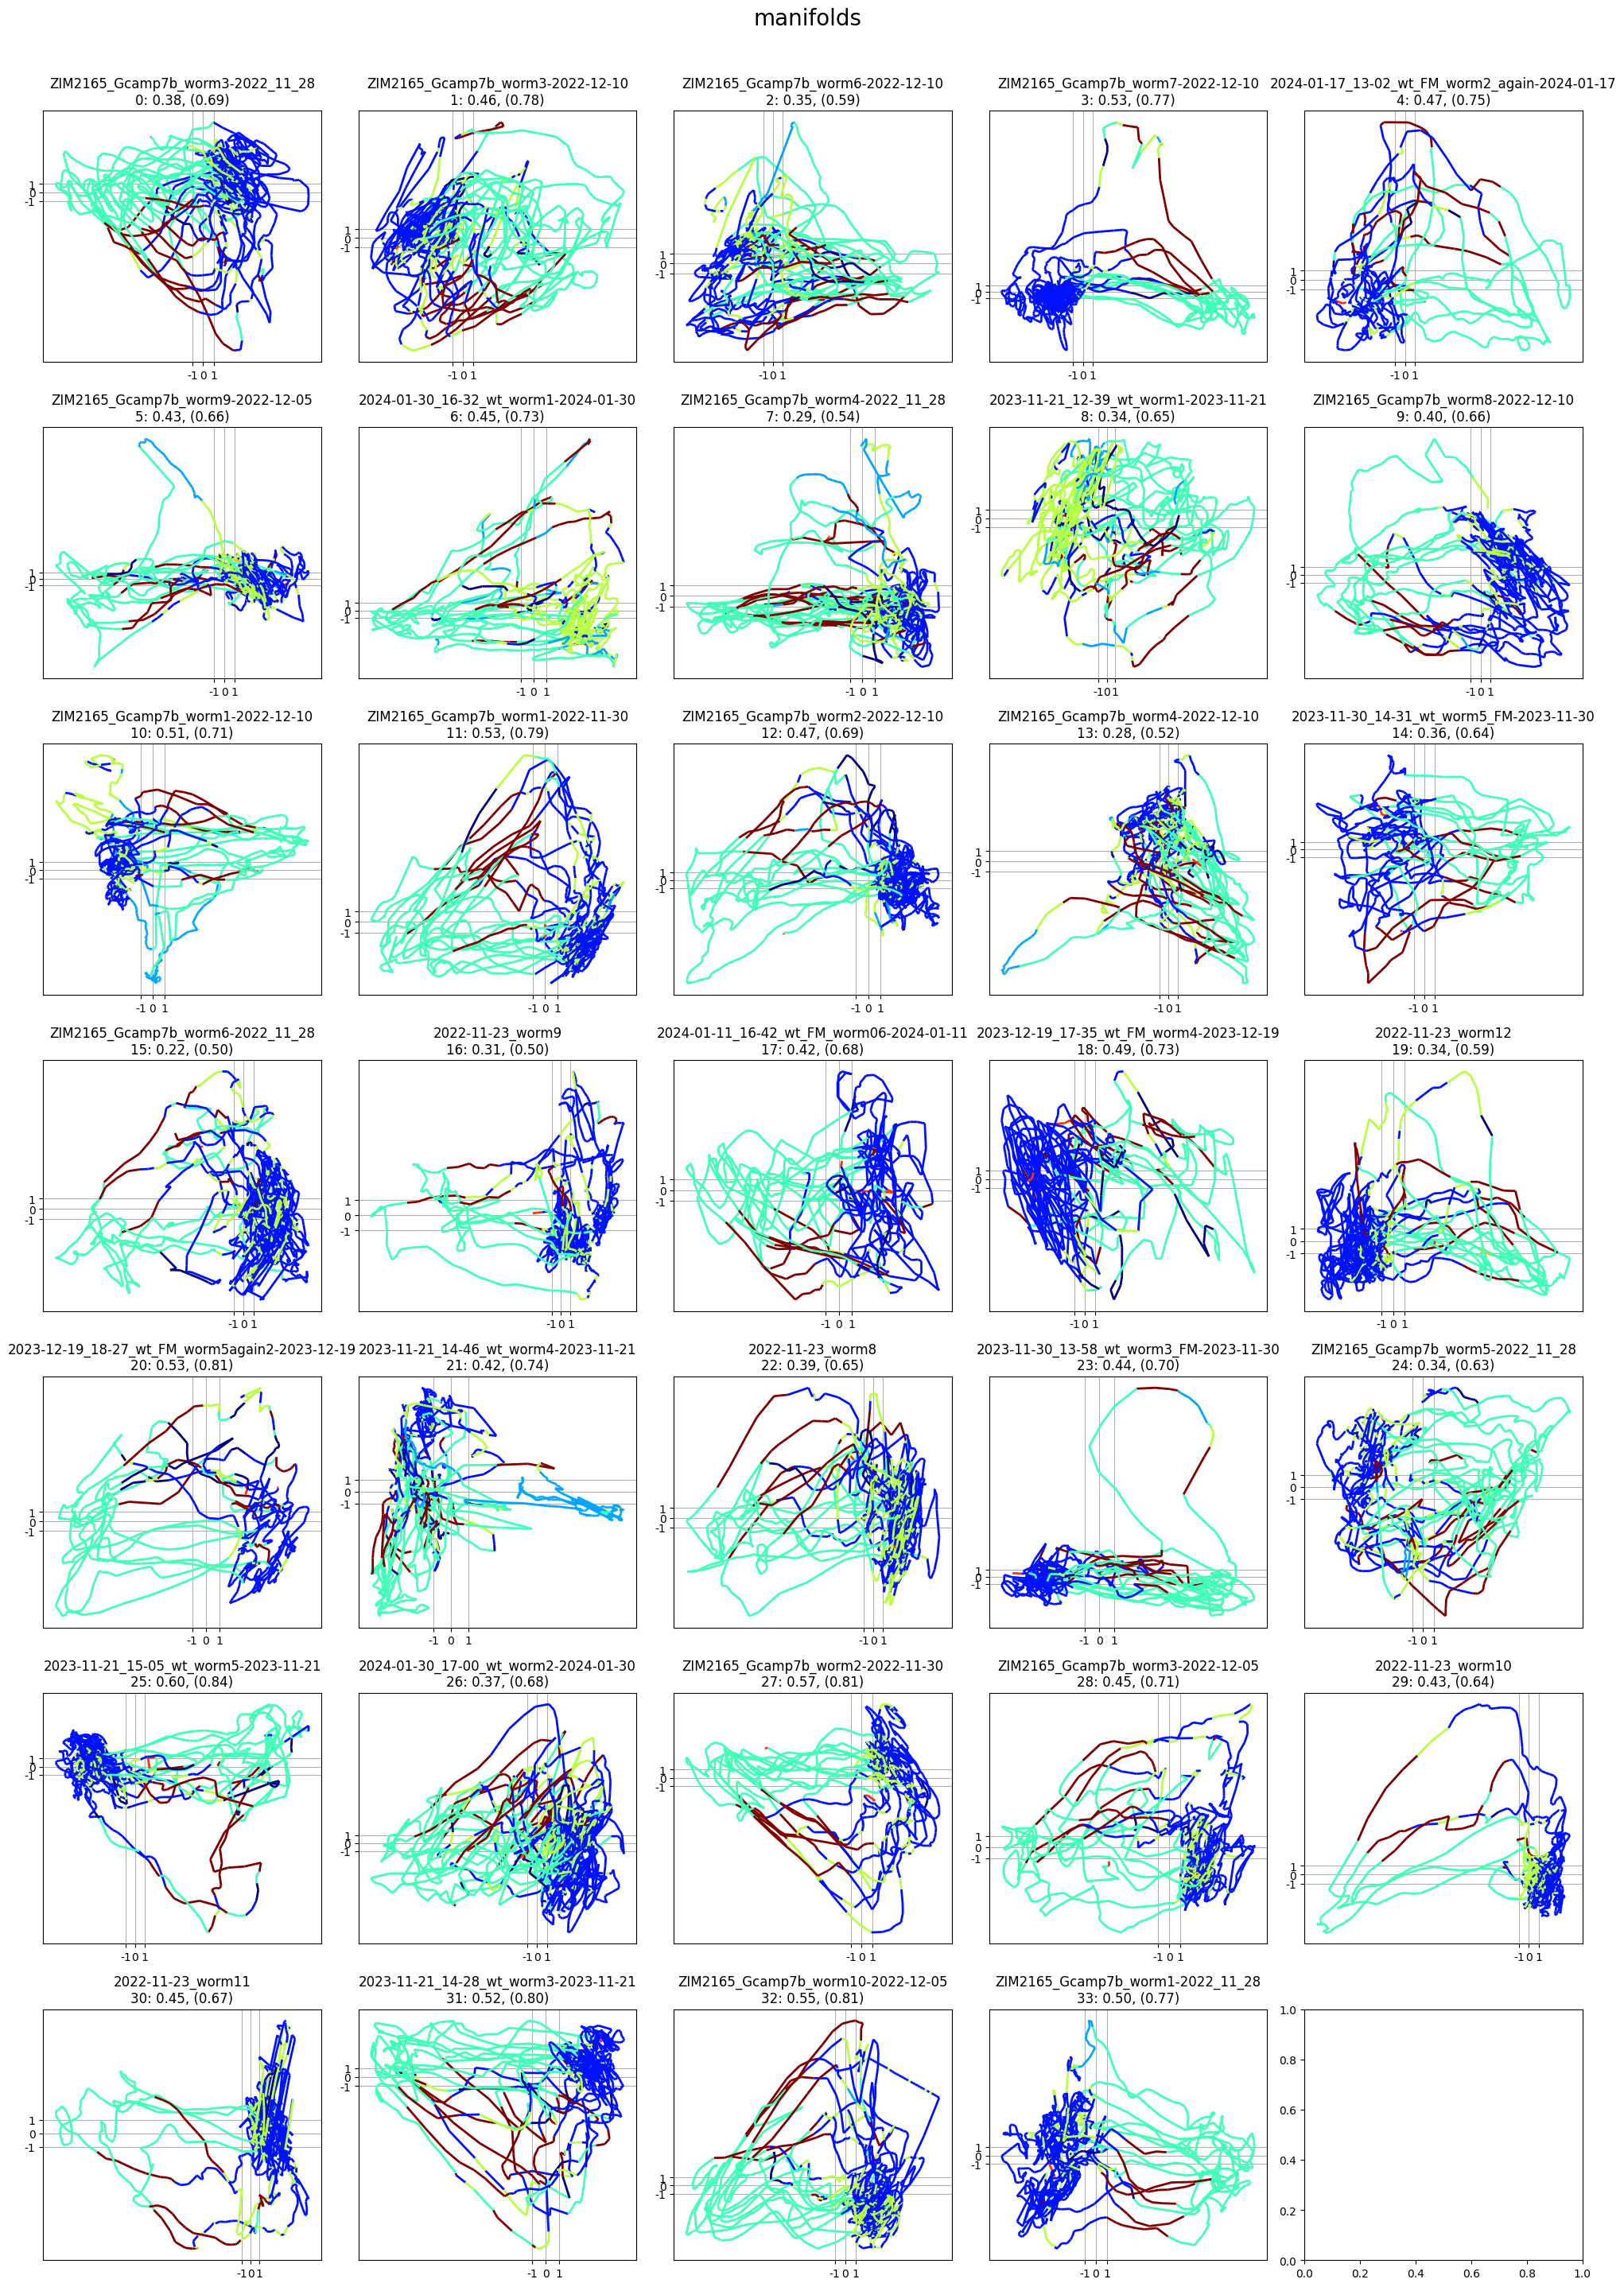

In [9]:
plot_utils.plot_manifolds(filenames, modes_manifold[0], discrete_states, vars_expl, vars_expl_rs)

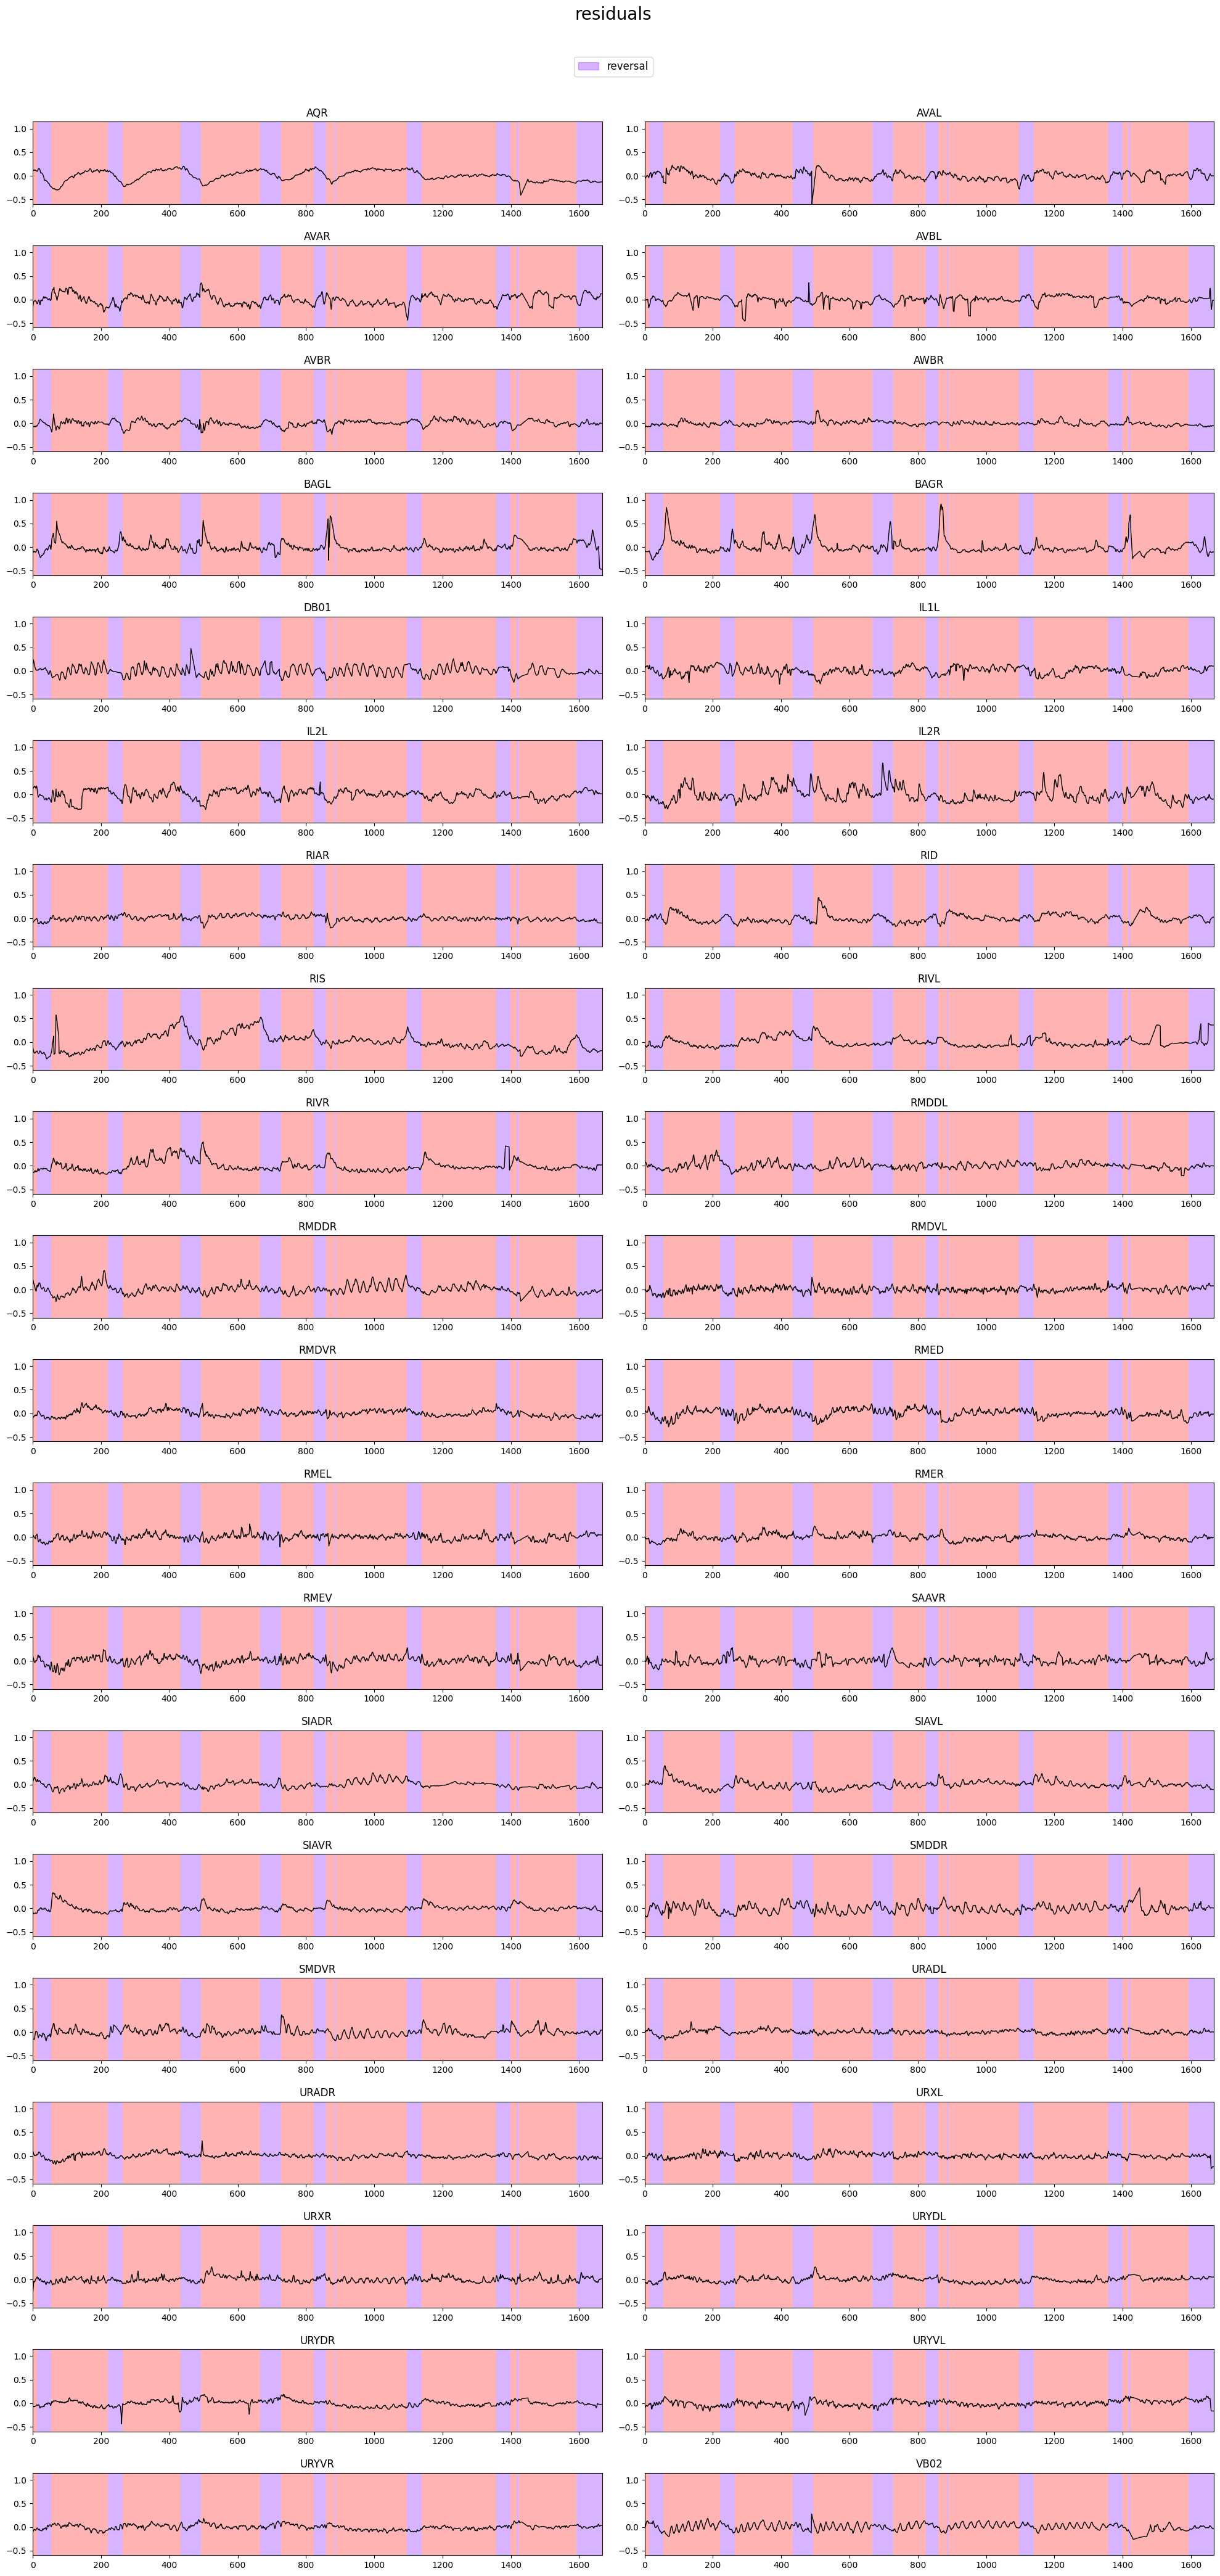

In [22]:
traces_residual = [trace - trace_man for trace, trace_man in zip(traces, recon_manifold[0])]

worm_id = 33
plot_utils.plot_traces('residuals',
					   discrete_states[worm_id]['REV'],
					   traces_residual[worm_id],
					   n_plots=None, plots_per_row=2, ylimits=None, top_space=2)